**Importing Libraries**

In [1]:
# --- Core Data & Numerics ---
import numpy as np
import pandas as pd
import joblib

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Preprocessing & Pipeline ---
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Models ---
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# --- Evaluation Metrics ---
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.shape

(7043, 21)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [9]:
(df["TotalCharges"].astype(str).str.strip() == "").sum()

np.int64(11)

Fixing TotalCharges

In [10]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

In [12]:
df["TotalCharges"].dtype

dtype('float64')

In [13]:
df["TotalCharges"].isnull().sum()

np.int64(11)

# **Checking 11 missing values of 7043**

In [14]:
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [15]:
# Removing only 11 rows
df.dropna(subset=["TotalCharges"], inplace=True)

In [16]:
df.shape

(7032, 21)

# **Checking Duplicate Customers**

In [17]:
#checking duplicate customer IDs:
df["customerID"].duplicated().sum()

np.int64(0)

# **Checking the Target Variable**

In [18]:
df["Churn"].value_counts()

,count
Churn,
No,5163
Yes,1869


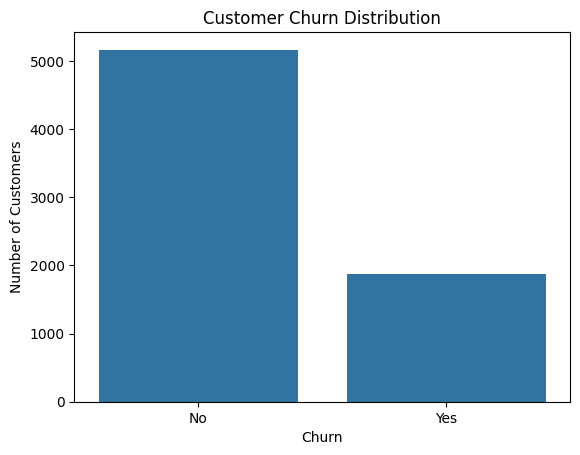

In [19]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [20]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.421502
Yes,26.578498


In [21]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.722826,11.277174
Two year,97.151335,2.848665


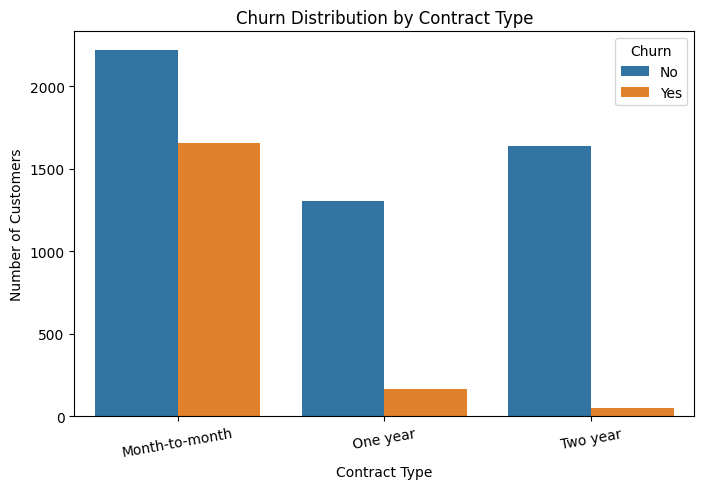

In [22]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=10)

plt.show()

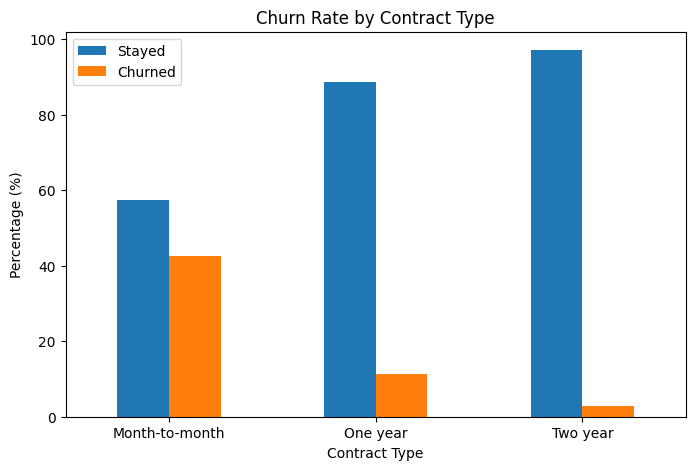

In [23]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])

plt.show()

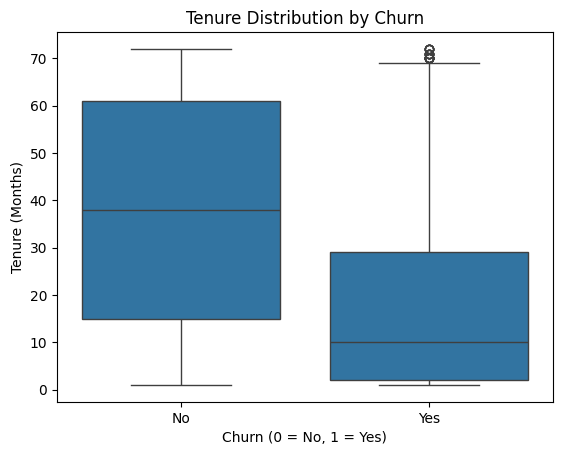

In [24]:
sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Tenure (Months)")

plt.show()

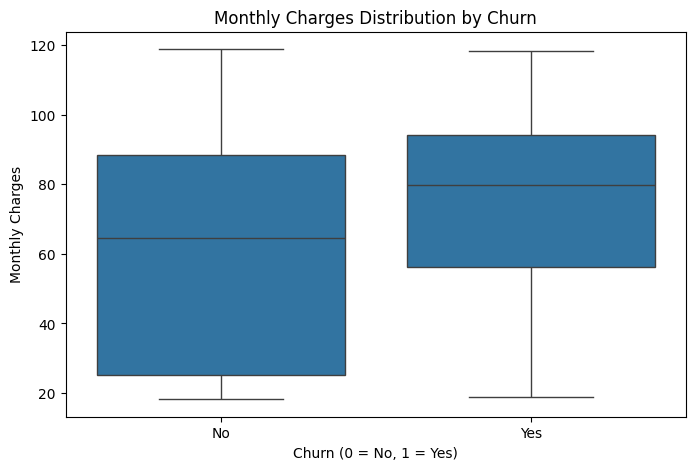

In [25]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Monthly Charges")

plt.show()

In [26]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
InternetService,,
DSL,81.001656,18.998344
Fiber optic,58.107235,41.892765
No,92.565789,7.434211


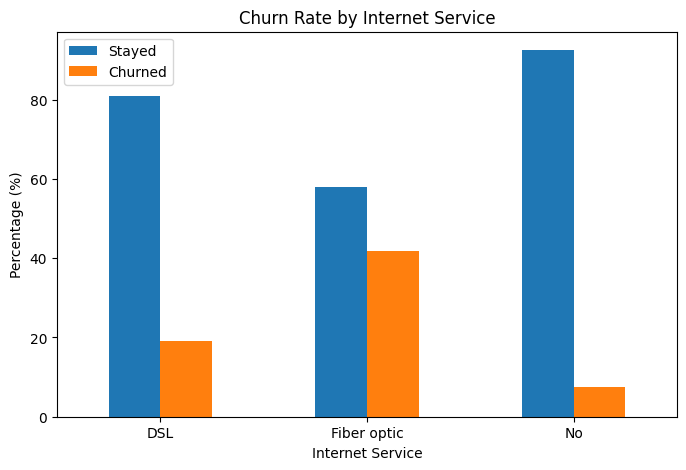

In [27]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])

plt.show()

In [28]:
tech_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print(tech_churn)

Churn                       No        Yes
TechSupport                              
No                   58.352535  41.647465
No internet service  92.565789   7.434211
Yes                  84.803922  15.196078


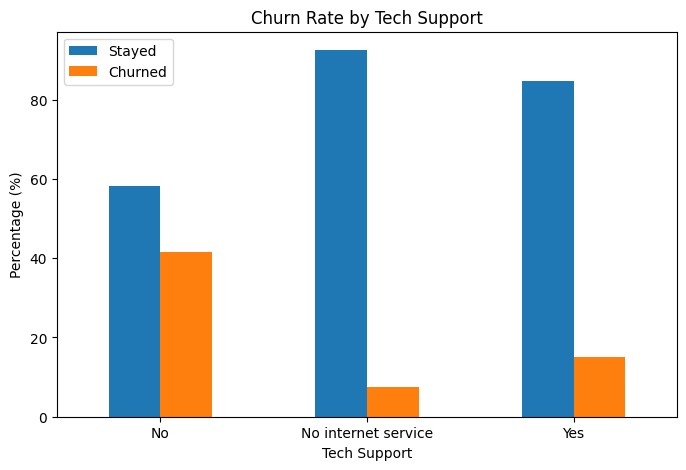

In [29]:
tech_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])

plt.show()

In [30]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [31]:
df.drop("customerID", axis=1, inplace=True)

# **Preparing Features and Target**
x → input features
y → what we want to predict (Churn)

In [32]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [33]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (7032, 19)
Target: (7032,)


# **Identifying Numerical & Categorical Columns**

In [34]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# **Train/Test Split**

In [35]:
"""
80% → training

20% → testing
"""

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# **Creating the Preprocessing Pipeline**

In [36]:
"""
Numerical columns -> StandardScaler

Categorical columns -> OneHotEncoder
"""

'\nNumerical columns -> StandardScaler\n\nCategorical columns -> OneHotEncoder\n'

In [37]:
# Creating Transformer -
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# **Model Training**

In [38]:
# Baseline Model (LogisticRegression)
log_reg_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

log_reg_pipe.fit(X_train, y_train)

y_pred = log_reg_pipe.predict(X_test)
y_proba = log_reg_pipe.predict_proba(X_test)[:, 1]  # probability of "Yes"

# Evaluate baseline test performance
print("ROC-AUC Score:", round(roc_auc_score(y_test == "Yes", y_proba), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

ROC-AUC Score: 0.8359

Confusion Matrix:
 [[917 116]
 [160 214]]

Classification Report:
               precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [39]:
# Compare baseline models (Logistic Regression, Random Forest, Gradient Boosting)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

# Fit each pipeline on training data and evaluate on held-out test set
for name, clf in models.items():
    pipe = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", clf),
        ]
    )
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test == "Yes", probs)
    print(f"=== {name} ===")
    print(f"ROC-AUC: {auc:.4f}")
    print(classification_report(y_test, preds, digits=3))

=== Logistic Regression ===
ROC-AUC: 0.8359
              precision    recall  f1-score   support

          No      0.851     0.888     0.869      1033
         Yes      0.648     0.572     0.608       374

    accuracy                          0.804      1407
   macro avg      0.750     0.730     0.739      1407
weighted avg      0.797     0.804     0.800      1407

=== Random Forest ===
ROC-AUC: 0.8140
              precision    recall  f1-score   support

          No      0.830     0.897     0.862      1033
         Yes      0.634     0.492     0.554       374

    accuracy                          0.790      1407
   macro avg      0.732     0.695     0.708      1407
weighted avg      0.778     0.790     0.780      1407

=== Gradient Boosting ===
ROC-AUC: 0.8386
              precision    recall  f1-score   support

          No      0.840     0.893     0.865      1033
         Yes      0.641     0.529     0.580       374

    accuracy                          0.796      1407
   m

# **Step 1: Add High-Signal Engineered Features Before Splitting**

In [40]:
# Start from your cleaned df (before creating X and y)
df_fe = df.copy()

# 1. Tenure lifecycle buckets
df_fe["tenure_group"] = pd.cut(
    df_fe["tenure"],
    bins=[0, 12, 24, 48, 100],
    labels=["0-12m", "13-24m", "25-48m", "49m+"],
    include_lowest=True,
).astype(str)

# 2. # Ratio of actual TotalCharges to tenure * MonthlyCharges (defaults to 1.0 when tenure is 0)
expected_charges = df_fe["tenure"] * df_fe["MonthlyCharges"]
df_fe["charge_ratio"] = np.where(
    expected_charges > 0, df_fe["TotalCharges"] / expected_charges, 1.0
)

# 3. Count of active optional add-on services
addon_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]
df_fe["active_addons_count"] = (df_fe[addon_cols] == "Yes").sum(axis=1)

# 4. Combined risk flag: Fiber optic + Month-to-month
df_fe["high_risk_fiber_mtm"] = (
    (df_fe["InternetService"] == "Fiber optic")
    & (df_fe["Contract"] == "Month-to-month")
).astype(int)

# **Step 2: Re-Split, Rebuild preprocessor, and Compare Models**

In [41]:
X_fe = df_fe.drop("Churn", axis=1)
y_fe = df_fe["Churn"]

# Stratified 80/20 split to preserve churn class balance
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.20, random_state=42, stratify=y_fe
)

# Separate numeric and categorical columns and build preprocessing pipeline
num_cols_fe = X_train_fe.select_dtypes(include=["int64", "float64"]).columns
cat_cols_fe = X_train_fe.select_dtypes(include=["object"]).columns

preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols_fe),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_fe),
    ]
)

models_fe = {
    "Logistic Regression (FE)": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Random Forest (FE)": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting (FE)": GradientBoostingClassifier(random_state=42),
}

# Train and evaluate each engineered-feature pipeline
for name, clf in models_fe.items():
  pipe = Pipeline(
      steps=[("preprocessor", preprocessor_fe), ("model", clf)]
  )
  pipe.fit(X_train_fe, y_train_fe)
  preds = pipe.predict(X_test_fe)
  probs = pipe.predict_proba(X_test_fe)[:, 1]
  print(f"=== {name} ===")
  print(f"ROC-AUC: {roc_auc_score(y_test_fe == 'Yes', probs):.4f}")
  print(classification_report(y_test_fe, preds, digits=3))

=== Logistic Regression (FE) ===
ROC-AUC: 0.8349
              precision    recall  f1-score   support

          No      0.839     0.890     0.863      1033
         Yes      0.633     0.527     0.575       374

    accuracy                          0.793      1407
   macro avg      0.736     0.708     0.719      1407
weighted avg      0.784     0.793     0.787      1407

=== Random Forest (FE) ===
ROC-AUC: 0.8127
              precision    recall  f1-score   support

          No      0.829     0.886     0.856      1033
         Yes      0.611     0.495     0.547       374

    accuracy                          0.782      1407
   macro avg      0.720     0.690     0.701      1407
weighted avg      0.771     0.782     0.774      1407

=== Gradient Boosting (FE) ===
ROC-AUC: 0.8370
              precision    recall  f1-score   support

          No      0.836     0.888     0.861      1033
         Yes      0.626     0.519     0.567       374

    accuracy                          0.790

In [42]:
# 1. Train, Evaluate & Save the Logistic Regression Pipeline
best_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

best_pipe.fit(X_train, y_train)

y_pred = best_pipe.predict(X_test)
y_proba = best_pipe.predict_proba(X_test)[:, 1]

print(f"Test ROC-AUC: {roc_auc_score(y_test == 'Yes', y_proba):.4f}")
print(classification_report(y_test, y_pred, digits=3))

# Persist trained pipeline to disk for downstream scoring
joblib.dump(best_pipe, "churn_logreg_pipeline.joblib")
print("Saved pipeline to churn_logreg_pipeline.joblib")

Test ROC-AUC: 0.8359
              precision    recall  f1-score   support

          No      0.851     0.888     0.869      1033
         Yes      0.648     0.572     0.608       374

    accuracy                          0.804      1407
   macro avg      0.750     0.730     0.739      1407
weighted avg      0.797     0.804     0.800      1407

Saved pipeline to churn_logreg_pipeline.joblib


In [43]:
# 2. Score Customers & Generate Retention Recommendations

def predict_churn_and_recommend(customers_df: pd.DataFrame, model_pipe=best_pipe):
  """Returns churn probability, risk tier, and tailored retention actions."""
  probs = model_pipe.predict_proba(customers_df)[:, 1]
  results = []

  for idx, prob in enumerate(probs):
    row = customers_df.iloc[idx]
    actions = []

    # Rule-based retention triggers ordered by contract, service/support, tenure, and billing
    if row.get("Contract") == "Month-to-month":
      actions.append("Offer annual/two-year contract discount or lock-in perk")
    if row.get("InternetService") == "Fiber optic" and row.get("TechSupport") != "Yes":
      actions.append("Provide onboarding check-in + TechSupport trial")
    if row.get("tenure", 99) <= 12:
      actions.append("Trigger early-tenure check-in / loyalty credit")
    if row.get("MonthlyCharges", 0) >= 75 and not actions:
      actions.append("Review plan bundle / bill optimization")
    if not actions:
      actions.append("Maintain standard engagement")

    # Map predicted churn probability into risk tiers
    if prob >= 0.60:
      risk_tier = "High"
    elif prob >= 0.35:
      risk_tier = "Medium"
    else:
      risk_tier = "Low"

    results.append({
        "churn_probability": round(float(prob), 4),
        "risk_tier": risk_tier,
        "recommended_actions": " | ".join(actions),
    })

  return pd.DataFrame(results, index=customers_df.index)

# Score test set and display top 10 highest-risk customers
scored_test = predict_churn_and_recommend(X_test)
top_at_risk = (
    X_test.assign(
        churn_prob=scored_test["churn_probability"],
        risk_tier=scored_test["risk_tier"],
        recommended_actions=scored_test["recommended_actions"],
    )
    .sort_values("churn_prob", ascending=False)
    .head(10)
)

display(
    top_at_risk[[
        "tenure",
        "Contract",
        "InternetService",
        "TechSupport",
        "MonthlyCharges",
        "churn_prob",
        "risk_tier",
        "recommended_actions",
    ]]
)

,tenure,Contract,InternetService,TechSupport,MonthlyCharges,churn_prob,risk_tier,recommended_actions
3380,1,Month-to-month,Fiber optic,No,95.10,0.8475,High,Offer annual/two-year contract discount or loc...
3159,3,Month-to-month,Fiber optic,No,94.85,0.8458,High,Offer annual/two-year contract discount or loc...
2631,7,Month-to-month,Fiber optic,No,99.25,0.8267,High,Offer annual/two-year contract discount or loc...
4585,1,Month-to-month,Fiber optic,No,85.05,0.8225,High,Offer annual/two-year contract discount or loc...
3727,3,Month-to-month,Fiber optic,No,96.60,0.8160,High,Offer annual/two-year contract discount or loc...
2797,3,Month-to-month,Fiber optic,No,100.95,0.8160,High,Offer annual/two-year contract discount or loc...
582,4,Month-to-month,Fiber optic,No,89.20,0.8156,High,Offer annual/two-year contract discount or loc...
933,4,Month-to-month,Fiber optic,No,84.60,0.8106,High,Offer annual/two-year contract discount or loc...
6240,1,Month-to-month,Fiber optic,No,93.30,0.7937,High,Offer annual/two-year contract discount or loc...
2516,16,Month-to-month,Fiber optic,No,96.40,0.7916,High,Offer annual/two-year contract discount or loc...


In [44]:
# --- Export Scored Dataset for Power BI ---
scored_test_df = predict_churn_and_recommend(X_test)

powerbi_df = X_test.copy()
powerbi_df["Actual_Churn"] = y_test.values
powerbi_df["churn_probability"] = scored_test_df["churn_probability"].values
powerbi_df["risk_tier"] = scored_test_df["risk_tier"].values
powerbi_df["recommended_actions"] = scored_test_df["recommended_actions"].values

# Optional: add tenure lifecycle buckets directly for easy slicing in Power BI
powerbi_df["tenure_group"] = pd.cut(
    powerbi_df["tenure"],
    bins=[0, 12, 24, 48, 100],
    labels=["0-12m", "13-24m", "25-48m", "49m+"],
    include_lowest=True,
).astype(str)

# Ensure numeric columns stay clean floats/ints for Power BI aggregation
for col in ["tenure", "MonthlyCharges", "TotalCharges", "churn_probability"]:
    if col in powerbi_df.columns:
        powerbi_df[col] = pd.to_numeric(powerbi_df[col], errors="coerce")

output_path = "powerbi_churn_data.csv"
powerbi_df.to_csv(output_path, index=False)

print(f"Exported '{output_path}' with shape {powerbi_df.shape}")
print("Risk tier counts:\n", powerbi_df["risk_tier"].value_counts())

Exported 'powerbi_churn_data.csv' with shape (1407, 24)
Risk tier counts:
 risk_tier
Low       913
Medium    282
High      212
Name: count, dtype: int64
